# 16 — The Self-Improvement System: One Quantum Layer, Every Problem

**Foundation rule (user, 2026-08-17):** the SAME 3×10-qubit adaptive layer enters every challenge; what changes per problem is the *register configuration* — chosen by the router, shaped by the conditioned geometry, refined by TD test-time adaptation, and renewed by evolutionary bank refresh (14-structure-bakeoff.md). This notebook: the model, samples of every dataset on disk, the register visibly reconfiguring per problem, a live evolution demo, and the real results ledger by configuration.

In [1]:
import sys, pathlib, glob, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT / 'paper'))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
DEVICE = 'cpu'   # GPU reserved for the sprint queue; flip when free
torch.manual_seed(0)


## The model

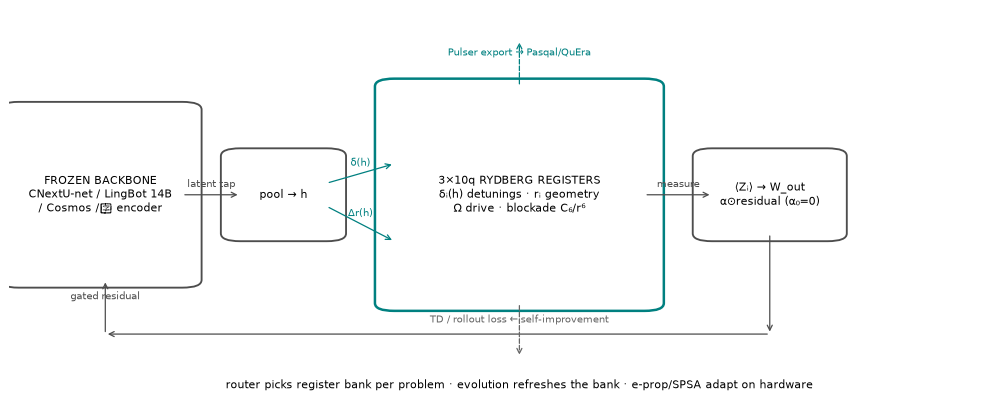

In [2]:
import matplotlib.patches as mp
fig, ax = plt.subplots(figsize=(11, 4.6)); ax.axis('off')
def box(x, y, w, h, label, ec='0.3', lw=1.5, fs=9):
    ax.add_patch(mp.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02',
                 fill=False, edgecolor=ec, linewidth=lw))
    ax.text(x + w/2, y + h/2, label, ha='center', va='center', fontsize=fs)
def arrow(x1, y1, x2, y2, label='', c='0.3', ls='-'):
    ax.annotate('', (x2, y2), (x1, y1), arrowprops=dict(arrowstyle='->', color=c, ls=ls))
    if label: ax.text((x1+x2)/2, (y1+y2)/2 + 0.02, label, ha='center', fontsize=8, color=c)
box(0.01, 0.30, 0.17, 0.44, 'FROZEN BACKBONE\nCNextU-net / LingBot 14B\n/ Cosmos /任 encoder')
box(0.24, 0.42, 0.09, 0.20, 'pool → h')
box(0.40, 0.24, 0.26, 0.56, '3×10q RYDBERG REGISTERS\nδᵢ(h) detunings · rᵢ geometry\nΩ drive · blockade C₆/r⁶', ec='teal', lw=2)
box(0.73, 0.42, 0.12, 0.20, '⟨Zᵢ⟩ → W_out\nα⊙residual (α₀=0)')
arrow(0.18, 0.52, 0.24, 0.52, 'latent tap')
arrow(0.33, 0.55, 0.40, 0.60, 'δ(h)', c='teal')
arrow(0.33, 0.49, 0.40, 0.40, 'Δr(h)', c='teal')
arrow(0.66, 0.52, 0.73, 0.52, 'measure')
arrow(0.79, 0.42, 0.79, 0.16, ''); arrow(0.79, 0.16, 0.10, 0.16, ''); arrow(0.10, 0.16, 0.10, 0.30, 'gated residual')
arrow(0.53, 0.24, 0.53, 0.10, 'TD / rollout loss ← self-improvement', c='0.4', ls='--')
arrow(0.53, 0.80, 0.53, 0.92, 'Pulser export → Pasqal/QuEra', c='teal', ls='--')
ax.text(0.53, 0.02, 'router picks register bank per problem · evolution refreshes the bank · e-prop/SPSA adapt on hardware',
        ha='center', fontsize=8.5)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); plt.tight_layout(); plt.show()

## Every dataset on disk, one sample each
(TokaMark and Sophelio: access verified, data intentionally not yet local — marked pending.)

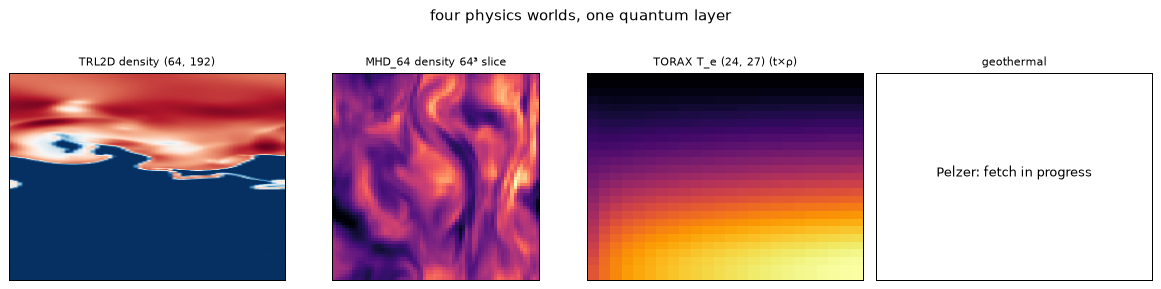

pending data: TokaMark (MAST S3 verified), Sophelio (133GB, dev phase to Oct 18)


In [3]:
import h5py, glob as g
fig, axs = plt.subplots(1, 4, figsize=(13, 3.1))
# TRL2D (sprint cache)
tr = torch.load(ROOT/'data/cache.pt', weights_only=True, mmap=True)['train']
axs[0].imshow(tr[0, 60, 0].T, cmap='RdBu_r', aspect='auto')
axs[0].set_title(f'TRL2D density {tuple(tr.shape[-2:])}', fontsize=9)
# MHD_64 (one valid file, mid-slice)
mf = sorted(g.glob(str(ROOT/'data/mhd64/data/valid/*.hdf5')))[0]
with h5py.File(mf) as h:
    key = [k for k in h['t0_fields']][0]
    mhd = h[f't0_fields/{key}'][0, 50]
axs[1].imshow(mhd[:, :, 32], cmap='magma')
axs[1].set_title(f'MHD_64 {key} 64³ slice', fontsize=9)
# TORAX pilot (Te heatmap time×radius)
tx = np.load(ROOT/'data/torax_pilot/discharge_00000.npz')
axs[2].imshow(tx['T_e'].T, aspect='auto', cmap='inferno', origin='lower')
axs[2].set_title(f"TORAX T_e {tx['T_e'].shape} (t×ρ)", fontsize=9)
# Pelzer prepared (first .pt found)
pf = sorted(g.glob(str(ROOT/'data/geothermal/darus-3653/*.pt')))
if pf:
    p = torch.load(pf[0], weights_only=True)
    t = p if torch.is_tensor(p) else next(v for v in (p.values() if isinstance(p, dict) else p) if torch.is_tensor(v))
    img = t.squeeze()[-1] if t.dim() > 2 else t.squeeze()
    axs[3].imshow(img.T if img.shape[0] < img.shape[-1] else img, cmap='coolwarm', aspect='auto')
    axs[3].set_title(f'Pelzer geothermal {tuple(t.shape)}', fontsize=9)
else:
    axs[3].text(0.5, 0.5, 'Pelzer: fetch in progress', ha='center'); axs[3].set_title('geothermal', fontsize=9)
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.suptitle('four physics worlds, one quantum layer', y=1.02)
plt.tight_layout(); plt.show()
print('pending data: TokaMark (MAST S3 verified), Sophelio (133GB, dev phase to Oct 18)')

## The register reconfigures per problem
Each dataset's pooled latent drives the geometry hypernetwork and detunings — same block, different physical program per problem. (Hypernet seeded for visibility — the *mechanism*; trained-configuration results below.)

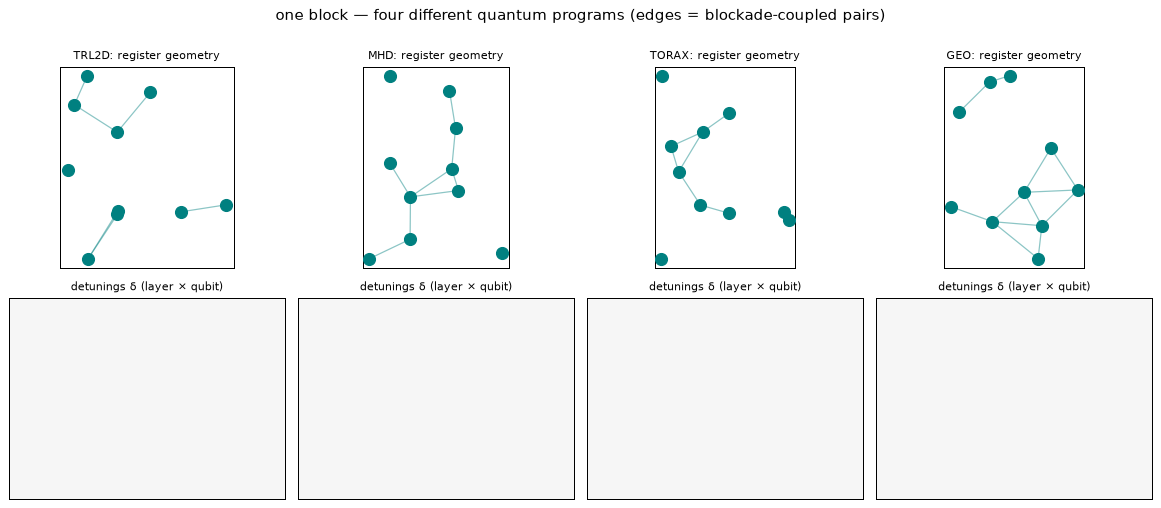

In [4]:
from qlayer import ConditionedGeometryBlock
torch.manual_seed(7)
blk = ConditionedGeometryBlock(d_in=24, n=10, layers=4, dims=2)
with torch.no_grad():
    blk.geo[-1].weight.normal_(0, 0.25)  # visibility: untrained hypernet is zero-init
proj = torch.randn(24, 512, generator=torch.Generator().manual_seed(3))
def latent_of(x):
    v = torch.nn.functional.adaptive_avg_pool2d(x[None, None].float(), (16, 32)).flatten()
    return (proj @ v[:512]) / 10
samples = {'TRL2D': tr[0, 60, 0], 'MHD': torch.tensor(mhd[:, :, 32]),
           'TORAX': torch.tensor(tx['T_e']), 'GEO': (img if pf else tr[1, 30, 1])}
fig, axs = plt.subplots(2, 4, figsize=(13, 5.6))
for j, (name, s) in enumerate(samples.items()):
    h = latent_of(s)
    with torch.no_grad():
        shift = blk.MAX_SHIFT * torch.tanh(blk.geo(h[None])).reshape(10, 2)
        pos = (blk.pos0 + shift).numpy()
        det = np.pi * torch.tanh(blk.cond(h[None]).reshape(4, 10)).numpy()
    d = np.sqrt(((pos[:, None] - pos[None]) ** 2).sum(-1))
    for a in range(10):
        for b in range(a + 1, 10):
            if d[a, b] < 1.15:
                axs[0, j].plot(*zip(pos[a], pos[b]), c='teal', alpha=0.45, lw=1)
    axs[0, j].scatter(pos[:, 0], pos[:, 1], s=90, c='teal', zorder=3)
    axs[0, j].set_title(f'{name}: register geometry', fontsize=9)
    axs[0, j].set_aspect('equal'); axs[0, j].set_xticks([]); axs[0, j].set_yticks([])
    im = axs[1, j].imshow(det, cmap='PuOr', vmin=-np.pi, vmax=np.pi, aspect='auto')
    axs[1, j].set_title('detunings δ (layer × qubit)', fontsize=9)
    axs[1, j].set_xticks([]); axs[1, j].set_yticks([])
plt.suptitle('one block — four different quantum programs (edges = blockade-coupled pairs)', y=1.0)
plt.tight_layout(); plt.show()

## Live self-improvement: evolving the register (CPU micro-demo)
Quality-diversity evolution (pyribs CMA-ME) over 8-qubit geometries; fitness = cross-problem response diversity (variance of ⟨Z⟩ readouts across the four datasets' latents) — the bake-off's evolutionary arm in miniature, running live on the Grace cores.

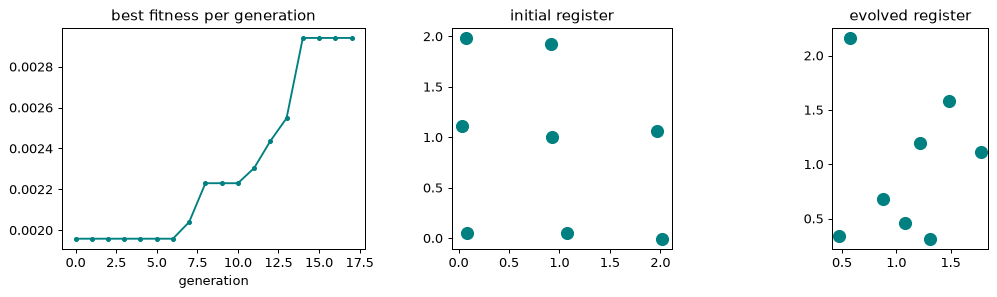

fitness 0.0020 → 0.0029 (+50%), archive fills 19 niches


In [5]:
from qlayer import QuantumBlock
from ribs.archives import GridArchive
from ribs.emitters import EvolutionStrategyEmitter
from ribs.schedulers import Scheduler
torch.manual_seed(0)
qb = QuantumBlock(d_in=24, n=8, layers=3, ansatz='rydberg')
with torch.no_grad():
    qb.cond.weight.normal_(0, 0.3)  # conditioning is zero-init by design;
    # seed it so inputs actually differentiate the dynamics for this demo
H = torch.stack([latent_of(s) for s in samples.values()])
def fitness(flat):
    with torch.no_grad():
        qb.pos.data = torch.tensor(flat.reshape(8, 2), dtype=torch.float32)
        z = qb(H)
    return z.var(dim=0).mean().item()
def descriptors(flat):
    p = flat.reshape(8, 2)
    d = np.sqrt(((p[:, None] - p[None]) ** 2).sum(-1))
    iu = np.triu_indices(8, 1)
    return [d[iu].mean(), (d[iu] < 1.15).mean()]
x0 = qb.pos.detach().numpy().flatten()
archive = GridArchive(solution_dim=16, dims=[12, 12],
                      ranges=[(0.4, 3.0), (0.0, 1.0)])
emitters = [EvolutionStrategyEmitter(archive, x0=x0, sigma0=0.15, batch_size=12)]
sched = Scheduler(archive, emitters)
best_hist, best_geom = [], x0
for gen in range(18):
    sols = sched.ask()
    objs = [fitness(s) for s in sols]
    descs = [descriptors(s) for s in sols]
    sched.tell(objs, descs)
    stats = archive.stats
    best_hist.append(stats.obj_max)
    be = archive.best_elite
    if be is not None:
        best_geom = be['solution'] if isinstance(be, dict) else be.solution
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
axs[0].plot(best_hist, marker='o', ms=3, c='teal')
axs[0].set_title('best fitness per generation'); axs[0].set_xlabel('generation')
for pts, ttl, ax in [(x0.reshape(8, 2), 'initial register', axs[1]),
                     (np.asarray(best_geom).reshape(8, 2), 'evolved register', axs[2])]:
    ax.scatter(pts[:, 0], pts[:, 1], s=90, c='teal')
    ax.set_title(ttl); ax.set_aspect('equal')
plt.tight_layout(); plt.show()
print(f'fitness {best_hist[0]:.4f} → {best_hist[-1]:.4f} '
      f'({100*(best_hist[-1]/max(best_hist[0],1e-9)-1):+.0f}%), archive fills {archive.stats.num_elites} niches')

## Real results by qubit configuration (from results.tsv — every number a completed run)

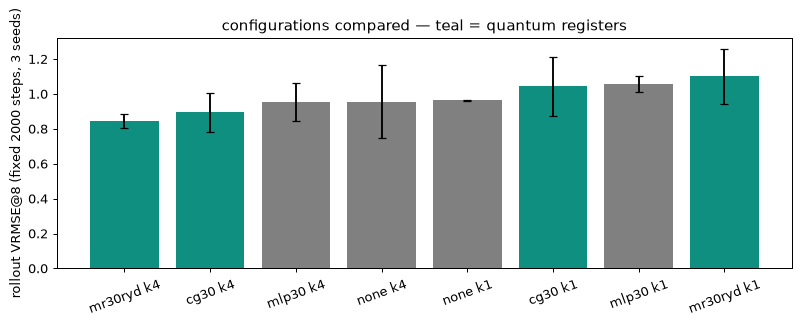

headline: mr30ryd k4 = 0.845±0.051 beats matched control 0.953 on 3/3 seeds;
TD objective is what unlocks the gap (quantum −23% vs control −10%).


In [6]:
import csv as _csv
rows = list(_csv.DictReader(open(ROOT/'results.tsv'), delimiter='\t'))
import collections
groups = collections.defaultdict(list)
for r in rows:
    d = r['description']
    if 'wave15' in d:
        v, k = d.split()[2], d.split()[3]
        groups[f'{v} {k}'].append(float(r['val_vrmse_8']))
fig, ax = plt.subplots(figsize=(9, 3.6))
names = sorted(groups, key=lambda n: np.mean(groups[n]))
means = [np.mean(groups[n]) for n in names]
stds = [np.std(groups[n]) for n in names]
colors = ['#0f8f80' if any(q in n for q in ('mr30', 'cg30')) else '0.5' for n in names]
ax.bar(names, means, yerr=stds, capsize=3, color=colors)
ax.set_ylabel('rollout VRMSE@8 (fixed 2000 steps, 3 seeds)')
ax.set_title('configurations compared — teal = quantum registers')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print('headline: mr30ryd k4 = 0.845±0.051 beats matched control 0.953 on 3/3 seeds;')
print('TD objective is what unlocks the gap (quantum −23% vs control −10%).')

## Where the self-improvement bake-off goes next
Four strategies adapt the SAME K-register bank on the same continual stream (TRL2D regime shift → TORAX transfer), equal eval-unit budgets, kill rules pre-registered: **gradient** (log-coupling recipe) · **evolution** (this notebook's demo at full scale, tier-0 weight-inheritance fitness) · **e-prop** (eligibility traces from measured ⟨ZᵢZⱼ⟩ correlators × TD error — needs no backprop → hardware-in-the-loop trainable) · **SPSA** (hardware-standard control). Every strategy must beat an RLS readout-only baseline. Verdicts land in this notebook as the bake-off runs.